In [1]:

import os
import re
import io
import base64
from pathlib import Path
from uuid import uuid4
from decimal import Decimal
from operator import add
from typing import Annotated
from typing_extensions import TypedDict
from getpass import getpass

import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver


# ============================================================
# 1. CONFIGURAÇÃO DO BANCO E DO MODELO
# ============================================================

DB_PATH = Path(
    globals().get("CAMINHO_DO_BANCO")
    or globals().get("DB_PATH")
    or r"C:\Users\eugen\Desktop\Kiro\clientes_novo_2.duckdb"
).expanduser().resolve()

if not DB_PATH.is_file():
    raise FileNotFoundError(
        f"Arquivo DuckDB não encontrado: {DB_PATH}"
    )

if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass(
        "OPENAI_API_KEY: "
    ).strip()

if not os.environ.get("OPENAI_API_KEY"):
    raise ValueError("OPENAI_API_KEY não configurada.")

model = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0,
    timeout=45,
    max_retries=1
)


def conectar():
    return duckdb.connect(
        str(DB_PATH),
        read_only=True,
        config={"enable_external_access": "false"}
    )


def texto_modelo(mensagem):
    conteudo = mensagem.content

    if isinstance(conteudo, str):
        return conteudo.strip()

    if isinstance(conteudo, list):
        partes = []

        for bloco in conteudo:
            if isinstance(bloco, str):
                partes.append(bloco)

            elif isinstance(bloco, dict):
                if bloco.get("type") in ("text", "output_text"):
                    texto = bloco.get("text", "")
                    if isinstance(texto, str):
                        partes.append(texto)

        texto = "\n".join(partes).strip()
        if texto:
            return texto

    raise ValueError("O modelo não retornou texto válido.")


# ============================================================
# 2. ESQUEMA DO BANCO
# ============================================================

def get_database_schema():
    with conectar() as con:
        colunas = con.execute(
            "DESCRIBE main.clientes"
        ).fetchall()

    schema = "Tabela: main.clientes\nColunas:\n"

    for nome, tipo, *_ in colunas:
        schema += f"- {nome} ({tipo})\n"

    return schema


# ============================================================
# 3. ESTADO DO AGENTE
# ============================================================

class AgentState(TypedDict):
    question: str
    table_schemas: str
    database: str
    sql: str
    reflect: Annotated[list[str], add]
    accepted: bool
    revision: int
    max_revision: int
    validation_error: str
    error: str
    results: list[tuple]
    columns: list[str]
    interpretation: str
    plot_html: str


# ============================================================
# 4. SEARCH ENGINEER
# ============================================================

def search_engineer_node(state: AgentState):
    return {
        "table_schemas": get_database_schema(),
        "database": str(DB_PATH)
    }


# ============================================================
# 5. SQL WRITER
# ============================================================

def sql_writer_node(state: AgentState):
    role_prompt = """
Você é especialista em SQL para DuckDB.

REGRAS OBRIGATÓRIAS:
1. Utilize exclusivamente a tabela main.clientes.
2. Utilize apenas as colunas do esquema fornecido.
3. Nunca invente tabelas como payments, Orders ou customers.
4. Gere somente uma consulta SELECT.
5. Retorne apenas SQL válido, sem markdown.
6. Balance representa saldo, não pagamentos.
7. Se a pergunta exigir dados inexistentes, retorne
   exatamente DADOS_INSUFICIENTES.
"""

    instruction = f"""
Esquema disponível:
{state['table_schemas']}

Pergunta:
{state['question']}
"""

    if state["reflect"]:
        instruction += (
            "\nErros de validação anteriores:\n"
            + "\n".join(state["reflect"])
        )

    messages = [
        SystemMessage(content=role_prompt),
        HumanMessage(content=instruction)
    ]

    response = model.invoke(messages)
    sql = texto_modelo(response)

    sql = re.sub(
        r"^```(?:sql)?\s*|\s*```$",
        "",
        sql,
        flags=re.I
    ).strip()

    print("\nSQL proposto:")
    print(sql)

    return {
        "sql": sql,
        "revision": state["revision"] + 1
    }


# ============================================================
# 6. QA ENGINEER
# ============================================================

def qa_engineer_node(state: AgentState):
    sql = state["sql"].strip()

    try:
        if sql == "DADOS_INSUFICIENTES":
            raise ValueError(
                "A pergunta exige informações ausentes no esquema."
            )

        if not re.match(r"(?is)^SELECT\b", sql):
            raise ValueError(
                "Somente consultas SELECT são permitidas."
            )

        if ";" in sql.rstrip("; \t\r\n"):
            raise ValueError(
                "Múltiplas instruções não são permitidas."
            )

        comandos_proibidos = (
            r"\b(?:COPY|ATTACH|DETACH|INSERT|UPDATE|DELETE|"
            r"CREATE|DROP|ALTER|CALL|PRAGMA|INSTALL|LOAD|"
            r"EXPORT|IMPORT)\b"
        )

        if re.search(comandos_proibidos, sql, re.I):
            raise ValueError(
                "SQL contém comando não permitido."
            )

        with conectar() as con:
            tabelas = {
                nome.lower().split(".")[-1]
                for nome in con.get_table_names(sql)
            }

            if tabelas != {"clientes"}:
                raise ValueError(
                    "Somente a tabela main.clientes é permitida. "
                    f"Tabelas encontradas: {tabelas}"
                )

            con.execute("EXPLAIN " + sql)

        print("QA: SQL validado pelo DuckDB.")

        return {
            "accepted": True,
            "validation_error": ""
        }

    except (ValueError, duckdb.Error) as exc:
        print("QA: SQL rejeitado:", exc)

        return {
            "accepted": False,
            "validation_error": str(exc)
        }


# ============================================================
# 7. CHIEF DBA
# ============================================================

def chief_dba_node(state: AgentState):
    feedback = (
        state["validation_error"]
        or "Corrija a consulta usando somente main.clientes."
    )

    print("CHIEF DBA: Solicitando revisão.")

    return {
        "reflect": [feedback]
    }


# ============================================================
# 8. EXECUTAR CONSULTA
# ============================================================

def execute_query_node(state: AgentState):
    try:
        with conectar() as con:
            cursor = con.execute(state["sql"])

            colunas = [
                descricao[0]
                for descricao in cursor.description
            ]

            linhas = cursor.fetchmany(101)

        truncado = len(linhas) > 100

        if truncado:
            linhas = linhas[:100]

        return {
            "results": linhas,
            "columns": colunas,
            "error": (
                "Resultado limitado às primeiras 100 linhas."
                if truncado else ""
            )
        }

    except duckdb.Error as exc:
        return {
            "results": [],
            "columns": [],
            "error": str(exc)
        }


# ============================================================
# 9. INTERPRETAR RESULTADOS
# ============================================================

def interpret_results_node(state: AgentState):
    if state["error"] and not state["results"]:
        return {
            "interpretation": (
                "A consulta não pôde ser executada: "
                + state["error"]
            )
        }

    if not state["results"]:
        return {
            "interpretation": "A consulta não retornou linhas."
        }

    instruction = f"""
Pergunta original:
{state['question']}

Colunas:
{state['columns']}

Resultados:
{state['results']}

Responda em português de maneira objetiva.
Utilize apenas os resultados fornecidos.
Não invente informações.
"""

    if state["error"]:
        instruction += (
            "\nA listagem está limitada a 100 linhas."
        )

    messages = [
        SystemMessage(
            content="Você interpreta resultados SQL com precisão."
        ),
        HumanMessage(content=instruction)
    ]

    response = model.invoke(messages)

    return {
        "interpretation": texto_modelo(response)
    }


# ============================================================
# 10. GERAR GRÁFICO
# ============================================================
from decimal import Decimal
import matplotlib.pyplot as plt
import io
import base64


def plot_results_node(state: AgentState):
    linhas = state["results"]
    colunas = state["columns"]

    if not (2 <= len(linhas) <= 30 and len(colunas) == 2):
        return {"plot_html": ""}

    if not all(
        len(linha) == 2 and isinstance(linha[1], (int, float, Decimal))
        for linha in linhas
    ):
        return {"plot_html": ""}

    labels = [str(linha[0]) for linha in linhas]
    values = [float(linha[1]) for linha in linhas]

    pergunta = state["question"].casefold()

    usar_pizza = any(termo in pergunta for termo in (
        "pizza",
        "setores",
        "percentual",
        "porcentagem",
        "proporção",
        "proporcao",
        "pie chart"
    ))

    if usar_pizza:
        total = sum(values)

        # gráfico de pizza só funciona bem com valores não negativos
        if total <= 0 or any(v < 0 for v in values):
            return {"plot_html": ""}

        fig, ax = plt.subplots(figsize=(7, 7))
        ax.pie(
            values,
            labels=labels,
            autopct="%1.1f%%",
            startangle=90
        )
        ax.set_title(state["question"])
        ax.axis("equal")

    else:
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.bar(labels, values)
        ax.set_xlabel(colunas[0])
        ax.set_ylabel(colunas[1])
        ax.set_title(state["question"])
        fig.autofmt_xdate(rotation=45)

    fig.tight_layout()

    buffer = io.BytesIO()
    fig.savefig(buffer, format="png")
    plt.close(fig)

    imagem = base64.b64encode(
        buffer.getvalue()
    ).decode("utf-8")

    return {
        "plot_html": (
            f'<img src="data:image/png;base64,{imagem}">'
        )
    }

# ============================================================
# 11. CONSTRUIR LANGGRAPH
# ============================================================

builder = StateGraph(AgentState)

nodes = {
    "search_engineer": search_engineer_node,
    "sql_writer": sql_writer_node,
    "qa_engineer": qa_engineer_node,
    "chief_dba": chief_dba_node,
    "execute_query": execute_query_node,
    "interpret_results": interpret_results_node,
    "plot_results": plot_results_node
}

for name, function in nodes.items():
    builder.add_node(name, function)

builder.add_edge(START, "search_engineer")
builder.add_edge("search_engineer", "sql_writer")
builder.add_edge("sql_writer", "qa_engineer")


def route_after_qa(state: AgentState):
    if state["accepted"]:
        return "execute_query"

    if state["sql"] == "DADOS_INSUFICIENTES":
        return "stop"

    if state["revision"] < state["max_revision"]:
        return "chief_dba"

    return "stop"


builder.add_conditional_edges(
    "qa_engineer",
    route_after_qa,
    {
        "execute_query": "execute_query",
        "chief_dba": "chief_dba",
        "stop": END
    }
)

builder.add_edge("chief_dba", "sql_writer")
builder.add_edge("execute_query", "interpret_results")
builder.add_edge("interpret_results", "plot_results")
builder.add_edge("plot_results", END)

graph = builder.compile(
    checkpointer=MemorySaver()
)


# ============================================================
# 12. FUNÇÃO PRINCIPAL
# ============================================================

def process_question(pergunta: str):
    initial_state: AgentState = {
        "question": pergunta,
        "table_schemas": "",
        "database": "",
        "sql": "",
        "reflect": [],
        "accepted": False,
        "revision": 0,
        "max_revision": 3,
        "validation_error": "",
        "error": "",
        "results": [],
        "columns": [],
        "interpretation": "",
        "plot_html": ""
    }

    config = {
        "configurable": {
            "thread_id": str(uuid4())
        }
    }

    for event in graph.stream(
        initial_state,
        config=config,
        stream_mode="updates"
    ):
        print(
            "Nó concluído:",
            ", ".join(event),
            flush=True
        )

    final_state = graph.get_state(config).values

    print("\nConsulta SQL gerada:")
    print(final_state["sql"])

    if not final_state["accepted"]:
        print(
            "Consulta não executada:",
            final_state["validation_error"]
        )
        return final_state

    if final_state["error"]:
        print("Aviso/erro:", final_state["error"])

    print("\nResultados:")

    if final_state["results"]:
        df = pd.DataFrame(
            final_state["results"],
            columns=final_state["columns"]
        )
        display(df)
    else:
        print("Nenhuma linha retornada.")

    print("\nInterpretação:")
    print(final_state["interpretation"])

    if final_state["plot_html"]:
        display(HTML(final_state["plot_html"]))
    else:
        print("Nenhum gráfico necessário.")

    return final_state


# ============================================================
# 13. EXECUTAR
# ============================================================

print("Banco utilizado:", DB_PATH)
print("\nEsquema encontrado:")
print(get_database_schema())

resultado = process_question(
    "Quantos clientes existem?"
)


Banco utilizado: C:\Users\eugen\Desktop\Kiro\clientes_novo_2.duckdb

Esquema encontrado:
Tabela: main.clientes
Colunas:
- RowNumber (BIGINT)
- CustomerId (BIGINT)
- Surname (VARCHAR)
- CreditScore (BIGINT)
- Geography (VARCHAR)
- Gender (VARCHAR)
- Age (BIGINT)
- Tenure (BIGINT)
- Balance (DOUBLE)
- NumOfProducts (BIGINT)
- HasCrCard (BIGINT)
- IsActiveMember (BIGINT)
- EstimatedSalary (DOUBLE)
- Exited (BIGINT)

Nó concluído: search_engineer

SQL proposto:
SELECT COUNT(*) AS total_clientes FROM main.clientes;
Nó concluído: sql_writer
QA: SQL validado pelo DuckDB.
Nó concluído: qa_engineer
Nó concluído: execute_query
Nó concluído: interpret_results
Nó concluído: plot_results

Consulta SQL gerada:
SELECT COUNT(*) AS total_clientes FROM main.clientes;

Resultados:


,total_clientes
0,10000



Interpretação:
Existem 10.000 clientes.
Nenhum gráfico necessário.


Nó concluído: search_engineer



SQL proposto:
SELECT Geography, COUNT(*) AS quantidade_clientes
FROM main.clientes
GROUP BY Geography;
Nó concluído: sql_writer
QA: SQL validado pelo DuckDB.
Nó concluído: qa_engineer
Nó concluído: execute_query
Nó concluído: interpret_results
Nó concluído: plot_results

Consulta SQL gerada:
SELECT Geography, COUNT(*) AS quantidade_clientes
FROM main.clientes
GROUP BY Geography;

Resultados:


,Geography,quantidade_clientes
0,France,5014
1,Spain,2477
2,Germany,2509



Interpretação:
A quantidade de clientes por região é a seguinte:

- França: 5014
- Espanha: 2477
- Alemanha: 2509

Para representar esses dados em um gráfico de pizza, você pode utilizar as proporções de cada região em relação ao total de clientes. 

Total de clientes: 5014 + 2477 + 2509 = 9990

Proporções:
- França: 5014 / 9990 ≈ 50,1%
- Espanha: 2477 / 9990 ≈ 24,8%
- Alemanha: 2509 / 9990 ≈ 25,1%

Com essas informações, você pode criar um gráfico de pizza que ilustra a distribuição de clientes por região.



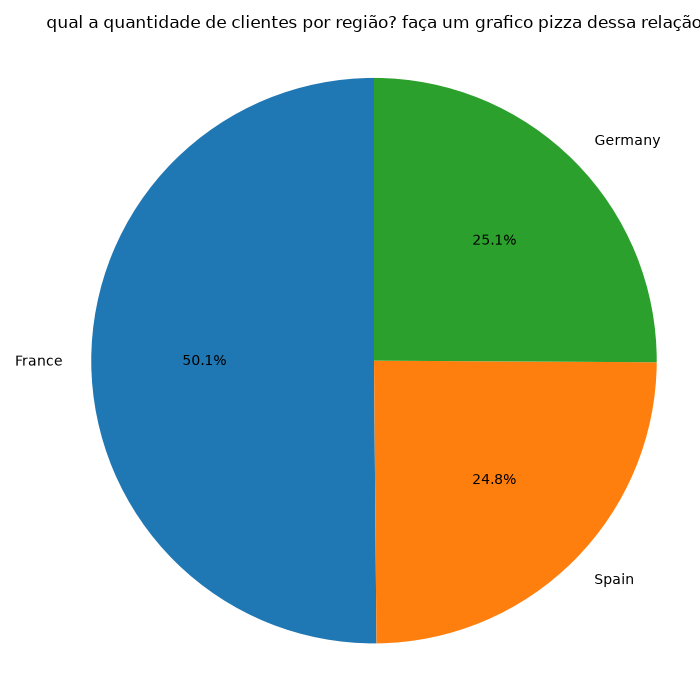

{'question': 'qual a quantidade de clientes por região? faça um grafico pizza dessa relação',
 'table_schemas': 'Tabela: main.clientes\nColunas:\n- RowNumber (BIGINT)\n- CustomerId (BIGINT)\n- Surname (VARCHAR)\n- CreditScore (BIGINT)\n- Geography (VARCHAR)\n- Gender (VARCHAR)\n- Age (BIGINT)\n- Tenure (BIGINT)\n- Balance (DOUBLE)\n- NumOfProducts (BIGINT)\n- HasCrCard (BIGINT)\n- IsActiveMember (BIGINT)\n- EstimatedSalary (DOUBLE)\n- Exited (BIGINT)\n',
 'database': 'C:\\Users\\eugen\\Desktop\\Kiro\\clientes_novo_2.duckdb',
 'sql': 'SELECT Geography, COUNT(*) AS quantidade_clientes\nFROM main.clientes\nGROUP BY Geography;',
 'reflect': [],
 'accepted': True,
 'revision': 1,
 'max_revision': 3,
 'validation_error': '',
 'error': '',
 'results': [['France', 5014], ['Spain', 2477], ['Germany', 2509]],
 'columns': ['Geography', 'quantidade_clientes'],
 'interpretation': 'A quantidade de clientes por região é a seguinte:\n\n- França: 5014\n- Espanha: 2477\n- Alemanha: 2509\n\nPara represen
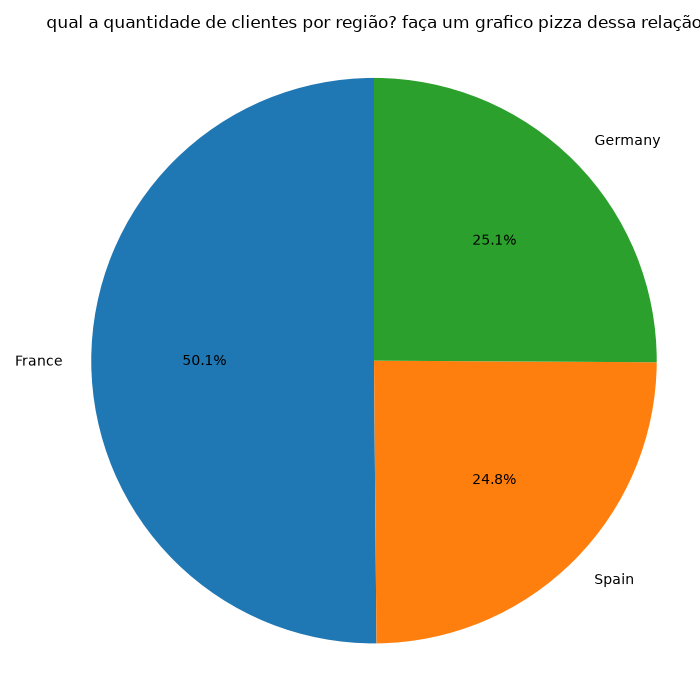

In [3]:
pergunta = "qual a quantidade de clientes por região? faça um grafico pizza dessa relação"
process_question(pergunta)

In [9]:
pergunta = "qual a quantidade dos generos masculino e feminino por país?"
process_question(pergunta)

Nó concluído: search_engineer



SQL proposto:
SELECT Geography, Gender, COUNT(*) AS Quantity
FROM main.clientes
GROUP BY Geography, Gender;
Nó concluído: sql_writer
QA: SQL validado pelo DuckDB.
Nó concluído: qa_engineer
Nó concluído: execute_query
Nó concluído: interpret_results
Nó concluído: plot_results

Consulta SQL gerada:
SELECT Geography, Gender, COUNT(*) AS Quantity
FROM main.clientes
GROUP BY Geography, Gender;

Resultados:


,Geography,Gender,Quantity
0,France,Female,2261
1,France,Male,2753
2,Spain,Male,1388
3,Germany,Male,1316
4,Spain,Female,1089
5,Germany,Female,1193



Interpretação:
A quantidade dos gêneros masculino e feminino por país é a seguinte:

- França:
  - Feminino: 2261
  - Masculino: 2753

- Espanha:
  - Feminino: 1089
  - Masculino: 1388

- Alemanha:
  - Feminino: 1193
  - Masculino: 1316
Nenhum gráfico necessário.


{'question': 'qual a quantidade dos generos masculino e feminino por país?',
 'table_schemas': 'Tabela: main.clientes\nColunas:\n- RowNumber (BIGINT)\n- CustomerId (BIGINT)\n- Surname (VARCHAR)\n- CreditScore (BIGINT)\n- Geography (VARCHAR)\n- Gender (VARCHAR)\n- Age (BIGINT)\n- Tenure (BIGINT)\n- Balance (DOUBLE)\n- NumOfProducts (BIGINT)\n- HasCrCard (BIGINT)\n- IsActiveMember (BIGINT)\n- EstimatedSalary (DOUBLE)\n- Exited (BIGINT)\n',
 'database': 'C:\\Users\\eugen\\Desktop\\Kiro\\clientes_novo_2.duckdb',
 'sql': 'SELECT Geography, Gender, COUNT(*) AS Quantity\nFROM main.clientes\nGROUP BY Geography, Gender;',
 'reflect': [],
 'accepted': True,
 'revision': 1,
 'max_revision': 3,
 'validation_error': '',
 'error': '',
 'results': [['France', 'Female', 2261],
  ['France', 'Male', 2753],
  ['Spain', 'Male', 1388],
  ['Germany', 'Male', 1316],
  ['Spain', 'Female', 1089],
  ['Germany', 'Female', 1193]],
 'columns': ['Geography', 'Gender', 'Quantity'],
 'interpretation': 'A quantidade d

Nó concluído: search_engineer



SQL proposto:
SELECT Geography, SUM(NumOfProducts) AS TotalProducts
FROM main.clientes
GROUP BY Geography;
Nó concluído: sql_writer
QA: SQL validado pelo DuckDB.
Nó concluído: qa_engineer
Nó concluído: execute_query
Nó concluído: interpret_results
Nó concluído: plot_results

Consulta SQL gerada:
SELECT Geography, SUM(NumOfProducts) AS TotalProducts
FROM main.clientes
GROUP BY Geography;

Resultados:


,Geography,TotalProducts
0,France,7676
1,Germany,3813
2,Spain,3813



Interpretação:
A quantidade de produtos por país é a seguinte:

- França: 7676 produtos
- Alemanha: 3813 produtos
- Espanha: 3813 produtos

Para representar esses dados em um gráfico de pizza, você pode utilizar as proporções de cada país em relação ao total de produtos. 

Se precisar de ajuda para criar o gráfico, posso orientar sobre como fazê-lo em ferramentas como Excel ou Python.



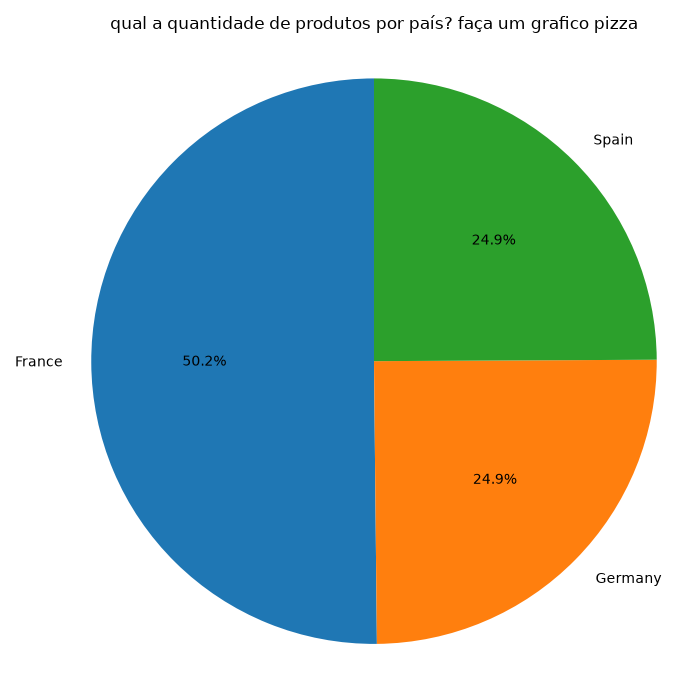

{'question': 'qual a quantidade de produtos por país? faça um grafico pizza',
 'table_schemas': 'Tabela: main.clientes\nColunas:\n- RowNumber (BIGINT)\n- CustomerId (BIGINT)\n- Surname (VARCHAR)\n- CreditScore (BIGINT)\n- Geography (VARCHAR)\n- Gender (VARCHAR)\n- Age (BIGINT)\n- Tenure (BIGINT)\n- Balance (DOUBLE)\n- NumOfProducts (BIGINT)\n- HasCrCard (BIGINT)\n- IsActiveMember (BIGINT)\n- EstimatedSalary (DOUBLE)\n- Exited (BIGINT)\n',
 'database': 'C:\\Users\\eugen\\Desktop\\Kiro\\clientes_novo_2.duckdb',
 'sql': 'SELECT Geography, SUM(NumOfProducts) AS TotalProducts\nFROM main.clientes\nGROUP BY Geography;',
 'reflect': [],
 'accepted': True,
 'revision': 1,
 'max_revision': 3,
 'validation_error': '',
 'error': '',
 'results': [['France', 7676], ['Germany', 3813], ['Spain', 3813]],
 'columns': ['Geography', 'TotalProducts'],
 'interpretation': 'A quantidade de produtos por país é a seguinte:\n\n- França: 7676 produtos\n- Alemanha: 3813 produtos\n- Espanha: 3813 produtos\n\nPara r
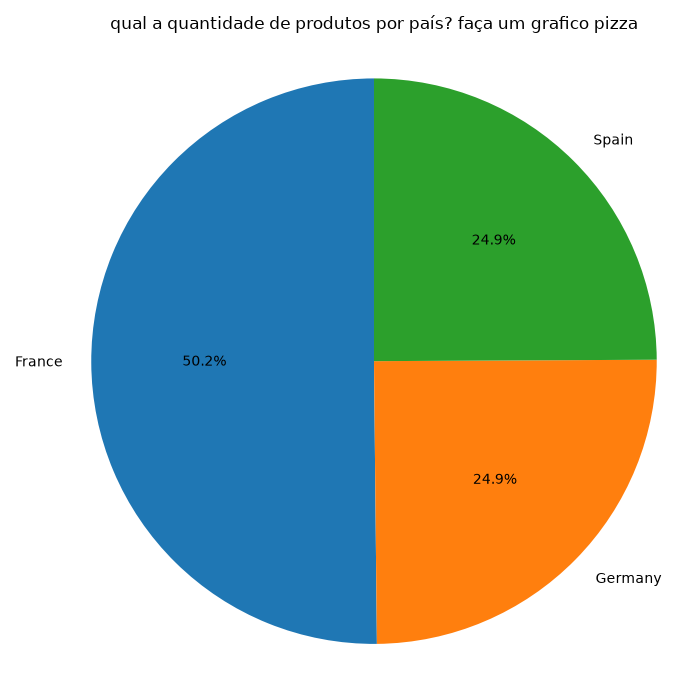

In [10]:
pergunta = "qual a quantidade de produtos por país? faça um grafico pizza"
process_question(pergunta)

Nó concluído: search_engineer



SQL proposto:
SELECT Gender, AVG(Age) AS AverageAge
FROM main.clientes
GROUP BY Gender;
Nó concluído: sql_writer
QA: SQL validado pelo DuckDB.
Nó concluído: qa_engineer
Nó concluído: execute_query
Nó concluído: interpret_results
Nó concluído: plot_results

Consulta SQL gerada:
SELECT Gender, AVG(Age) AS AverageAge
FROM main.clientes
GROUP BY Gender;

Resultados:


,Gender,AverageAge
0,Male,38.658237
1,Female,39.238389



Interpretação:
A média da idade entre homens é de 38,66 anos e entre mulheres é de 39,24 anos.



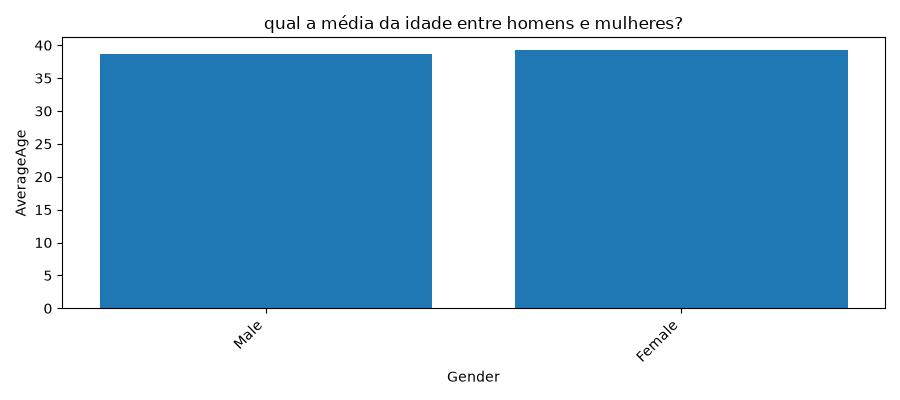

{'question': 'qual a média da idade entre homens e mulheres?',
 'table_schemas': 'Tabela: main.clientes\nColunas:\n- RowNumber (BIGINT)\n- CustomerId (BIGINT)\n- Surname (VARCHAR)\n- CreditScore (BIGINT)\n- Geography (VARCHAR)\n- Gender (VARCHAR)\n- Age (BIGINT)\n- Tenure (BIGINT)\n- Balance (DOUBLE)\n- NumOfProducts (BIGINT)\n- HasCrCard (BIGINT)\n- IsActiveMember (BIGINT)\n- EstimatedSalary (DOUBLE)\n- Exited (BIGINT)\n',
 'database': 'C:\\Users\\eugen\\Desktop\\Kiro\\clientes_novo_2.duckdb',
 'sql': 'SELECT Gender, AVG(Age) AS AverageAge\nFROM main.clientes\nGROUP BY Gender;',
 'reflect': [],
 'accepted': True,
 'revision': 1,
 'max_revision': 3,
 'validation_error': '',
 'error': '',
 'results': [['Male', 38.658237126626354], ['Female', 39.238388729914156]],
 'columns': ['Gender', 'AverageAge'],
 'interpretation': 'A média da idade entre homens é de 38,66 anos e entre mulheres é de 39,24 anos.',
 'plot_html': ''}
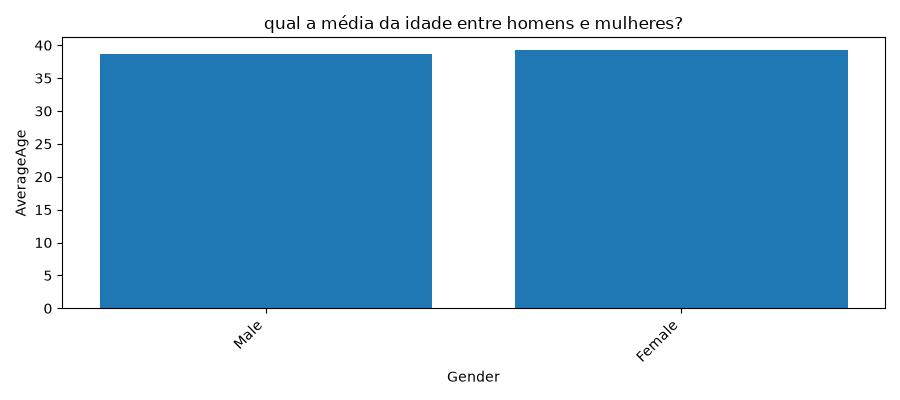

In [11]:
pergunta = "qual a média da idade entre homens e mulheres?"
process_question(pergunta)

In [18]:
pergunta = "Qual o menor e o maior CreditScore?"
process_question(pergunta)

Nó concluído: search_engineer



SQL proposto:
SELECT MIN(CreditScore) AS Menor_CreditScore, MAX(CreditScore) AS Maior_CreditScore FROM main.clientes;
Nó concluído: sql_writer
QA: SQL validado pelo DuckDB.
Nó concluído: qa_engineer
Nó concluído: execute_query
Nó concluído: interpret_results
Nó concluído: plot_results

Consulta SQL gerada:
SELECT MIN(CreditScore) AS Menor_CreditScore, MAX(CreditScore) AS Maior_CreditScore FROM main.clientes;

Resultados:


,Menor_CreditScore,Maior_CreditScore
0,350,850



Interpretação:
O menor CreditScore é 350 e o maior CreditScore é 850.
Nenhum gráfico necessário.


{'question': 'Qual o menor e o maior CreditScore?',
 'table_schemas': 'Tabela: main.clientes\nColunas:\n- RowNumber (BIGINT)\n- CustomerId (BIGINT)\n- Surname (VARCHAR)\n- CreditScore (BIGINT)\n- Geography (VARCHAR)\n- Gender (VARCHAR)\n- Age (BIGINT)\n- Tenure (BIGINT)\n- Balance (DOUBLE)\n- NumOfProducts (BIGINT)\n- HasCrCard (BIGINT)\n- IsActiveMember (BIGINT)\n- EstimatedSalary (DOUBLE)\n- Exited (BIGINT)\n',
 'database': 'C:\\Users\\eugen\\Desktop\\Kiro\\clientes_novo_2.duckdb',
 'sql': 'SELECT MIN(CreditScore) AS Menor_CreditScore, MAX(CreditScore) AS Maior_CreditScore FROM main.clientes;',
 'reflect': [],
 'accepted': True,
 'revision': 1,
 'max_revision': 3,
 'validation_error': '',
 'error': '',
 'results': [[350, 850]],
 'columns': ['Menor_CreditScore', 'Maior_CreditScore'],
 'interpretation': 'O menor CreditScore é 350 e o maior CreditScore é 850.',
 'plot_html': ''}

In [19]:
pergunta = "Qual o menor e o maior EstimatedSalary?"
process_question(pergunta)

Nó concluído: search_engineer

SQL proposto:
SELECT MIN(EstimatedSalary) AS Menor_EstimatedSalary, MAX(EstimatedSalary) AS Maior_EstimatedSalary FROM main.clientes;
Nó concluído: sql_writer
QA: SQL validado pelo DuckDB.
Nó concluído: qa_engineer
Nó concluído: execute_query
Nó concluído: interpret_results
Nó concluído: plot_results

Consulta SQL gerada:
SELECT MIN(EstimatedSalary) AS Menor_EstimatedSalary, MAX(EstimatedSalary) AS Maior_EstimatedSalary FROM main.clientes;

Resultados:


,Menor_EstimatedSalary,Maior_EstimatedSalary
0,11.58,199992.48



Interpretação:
O menor EstimatedSalary é 11.58 e o maior EstimatedSalary é 199992.48.
Nenhum gráfico necessário.


{'question': 'Qual o menor e o maior EstimatedSalary?',
 'table_schemas': 'Tabela: main.clientes\nColunas:\n- RowNumber (BIGINT)\n- CustomerId (BIGINT)\n- Surname (VARCHAR)\n- CreditScore (BIGINT)\n- Geography (VARCHAR)\n- Gender (VARCHAR)\n- Age (BIGINT)\n- Tenure (BIGINT)\n- Balance (DOUBLE)\n- NumOfProducts (BIGINT)\n- HasCrCard (BIGINT)\n- IsActiveMember (BIGINT)\n- EstimatedSalary (DOUBLE)\n- Exited (BIGINT)\n',
 'database': 'C:\\Users\\eugen\\Desktop\\Kiro\\clientes_novo_2.duckdb',
 'sql': 'SELECT MIN(EstimatedSalary) AS Menor_EstimatedSalary, MAX(EstimatedSalary) AS Maior_EstimatedSalary FROM main.clientes;',
 'reflect': [],
 'accepted': True,
 'revision': 1,
 'max_revision': 3,
 'validation_error': '',
 'error': '',
 'results': [[11.58, 199992.48]],
 'columns': ['Menor_EstimatedSalary', 'Maior_EstimatedSalary'],
 'interpretation': 'O menor EstimatedSalary é 11.58 e o maior EstimatedSalary é 199992.48.',
 'plot_html': ''}